# Imports

In [1]:
import sys
import time
import numpy as np
import matplotlib.pyplot as plt

sys.setrecursionlimit(10_000)  # globoki plazovi pri večjih mrežah

# Globalni parametri
Nx, Ny = 31, 31     # velikost mreže
S_c = 4             # kritična strmina
n_zrn = 1           # število zrn na iteracijo
T_FIN = 30_000      # število iteracij
tau_t = 1000        # interval merjenja časa

# Funkcije

In [2]:
def init_S(Nx, Ny):
    """Prazna mreža velikosti Nx x Ny (cela števila)."""
    return np.zeros((Nx, Ny), dtype=int)


def init_F(Nx, Ny, pos, n_zrn):
    """Matrika dodajanja: n_zrn na polju pos = (i, j), drugod 0."""
    F = np.zeros((Nx, Ny), dtype=int)
    F[pos[0], pos[1]] = n_zrn
    return F


def plaz(i, j, S, S_c, stanje):
    """Rekurzivno zruši polje (i, j), če S[i, j] > S_c.
    stanje["s"] šteje rušenja, stanje["izguba"] zrna, ki zapustijo mrežo."""
    if S[i, j] > S_c:
        stanje["s"] += 1
        S[i, j] -= 4
        for a, b in ((i + 1, j), (i - 1, j), (i, j + 1), (i, j - 1)):
            if 0 <= a < S.shape[0] and 0 <= b < S.shape[1]:
                S[a, b] += 1
                plaz(a, b, S, S_c, stanje)
            else:
                stanje["izguba"] += 1
    return S


def simulacija(Nx, Ny, S_c, n_zrn, T_FIN, tau_t=1000):
    """Vrne slovar s časovnimi vrstami: velikost plazu "s", vsota zrn "vsota",
    izgubljena zrna "izguba", čas na tau_t iteracij "dt" in končno stanje "S"."""
    S = init_S(Nx, Ny)
    F = init_F(Nx, Ny, (Nx // 2, Ny // 2), n_zrn)
    rez = {"s": [], "vsota": [], "izguba": [], "dt": []}
    t0 = time.time()
    for t in range(T_FIN):
        S += F
        stanje = {"s": 0, "izguba": 0}
        plaz(Nx // 2, Ny // 2, S, S_c, stanje)
        rez["s"].append(stanje["s"])
        rez["vsota"].append(S.sum())
        rez["izguba"].append(stanje["izguba"])
        if (t + 1) % tau_t == 0:
            rez["dt"].append(time.time() - t0)
            t0 = time.time()
    rez["S"] = S
    return {k: np.array(v) if k != "S" else v for k, v in rez.items()}


def drsece_povprecje(y, w):
    """Drseče povprečje širine w; vrne (x, y_gl), x je sredina okna."""
    y_gl = np.convolve(y, np.ones(w) / w, mode="valid")
    x = np.arange(len(y_gl)) + (w - 1) / 2
    return x, y_gl


def porazdelitev(velikosti):
    """Vrne (s, N(s)) za plazove z velikostjo > 0."""
    return np.unique(velikosti[velikosti > 0], return_counts=True)


def r2(y, y_fit):
    """Koeficient determinacije R^2."""
    return 1 - np.sum((y - y_fit) ** 2) / np.sum((y - np.mean(y)) ** 2)


def t_stac(izguba):
    """Prva iteracija, pri kateri zrno zapusti mrežo."""
    return int(np.argmax(izguba > 0))

# Testno območje

In [3]:
# Primer iz pripravljalne naloge P1
S_test = np.array([[2, 4, 2],
                   [4, 4, 4],
                   [2, 4, 2]])
vsota_prej = S_test.sum()
S_test[1, 1] += 1
stanje = {"s": 0, "izguba": 0}
plaz(1, 1, S_test, 4, stanje)

print(S_test)
print("s =", stanje["s"], "| izguba =", stanje["izguba"])
print("ohranitev peska:", vsota_prej + 1 == S_test.sum() + stanje["izguba"])

[[4 2 4]
 [2 1 2]
 [4 2 4]]
s = 6 | izguba = 4
ohranitev peska: True


# Naloga 1

In [4]:
# Preglednica 1: ročni rezultat iz P1 in primerjava z numeričnim
S_rocno = np.array([[4, 2, 4],
                    [2, 1, 2],
                    [4, 2, 4]])
s_rocno, izguba_rocno = 6, 4

print("S enak:", np.array_equal(S_rocno, S_test))
print("s enak:", s_rocno == stanje["s"], "| izguba enaka:", izguba_rocno == stanje["izguba"])

S enak: True
s enak: True | izguba enaka: True


# Naloga 2

In [5]:
rez = simulacija(Nx, Ny, S_c, n_zrn, T_FIN, tau_t)

# Naloga 2 - Slika 1

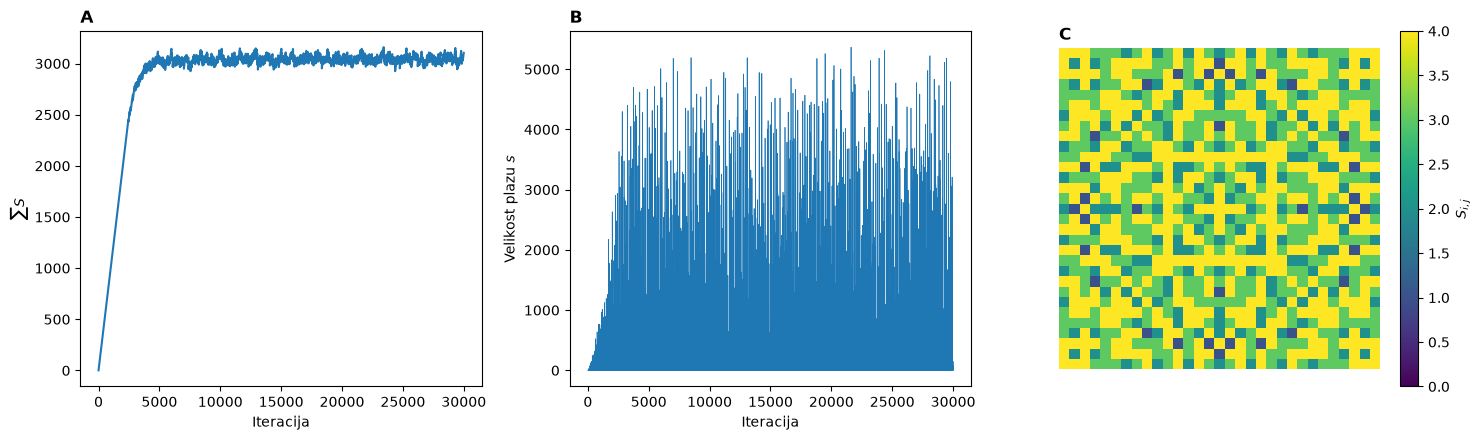

T_stac = 2448
<S> = 3.23 | izguba na iteracijo: 0.976
s_max = 5367


In [6]:
fig = plt.figure(figsize=(15, 4.5))

ax = fig.add_subplot(131)
ax.plot(rez["vsota"])
ax.set_xlabel("Iteracija")
ax.set_ylabel(r"$\sum S$")
ax.set_title("A", loc="left", fontweight="bold")

ax = fig.add_subplot(132)
ax.plot(rez["s"], lw=0.5)
ax.set_xlabel("Iteracija")
ax.set_ylabel("Velikost plazu $s$")
ax.set_title("B", loc="left", fontweight="bold")

ax = fig.add_subplot(133)
im = ax.imshow(rez["S"], cmap="viridis", vmin=0, vmax=S_c)
fig.colorbar(im, ax=ax, label="$S_{i,j}$")
ax.axis("off")
ax.set_title("C", loc="left", fontweight="bold")

fig.tight_layout()
plt.show()

T_stac = t_stac(rez["izguba"])
stac = slice(T_stac, None)
print("T_stac =", T_stac)
print("<S> =", round(rez["S"].mean(), 3), "| izguba na iteracijo:", round(rez["izguba"][stac].mean(), 3))
print("s_max =", rez["s"].max())

# Naloga 2 - Slika 2

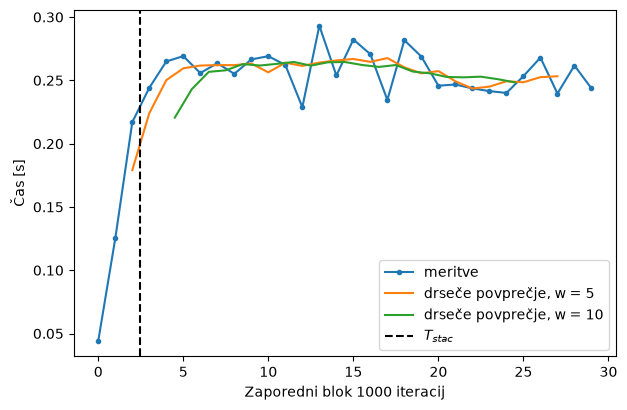

In [7]:
fig = plt.figure(figsize=(7, 4.5))
ax = fig.add_subplot(111)
ax.plot(rez["dt"], "o-", ms=3, label="meritve")
for w in (5, 10):
    x, y = drsece_povprecje(rez["dt"], w)
    ax.plot(x, y, label=f"drseče povprečje, w = {w}")
ax.axvline(T_stac / tau_t, color="k", ls="--", label="$T_{stac}$")
ax.set_xlabel(f"Zaporedni blok {tau_t} iteracij")
ax.set_ylabel("Čas [s]")
ax.legend()
plt.show()

# Naloga 3 - Slika 3

linearni:    k = -0.666, n = 146, R2 = 0.041
eksponentni: A = 21, B = 0.0073, R2 = 0.349
potenčni:    A = 1.28e+03, tau = 1.108, R2 = 0.737


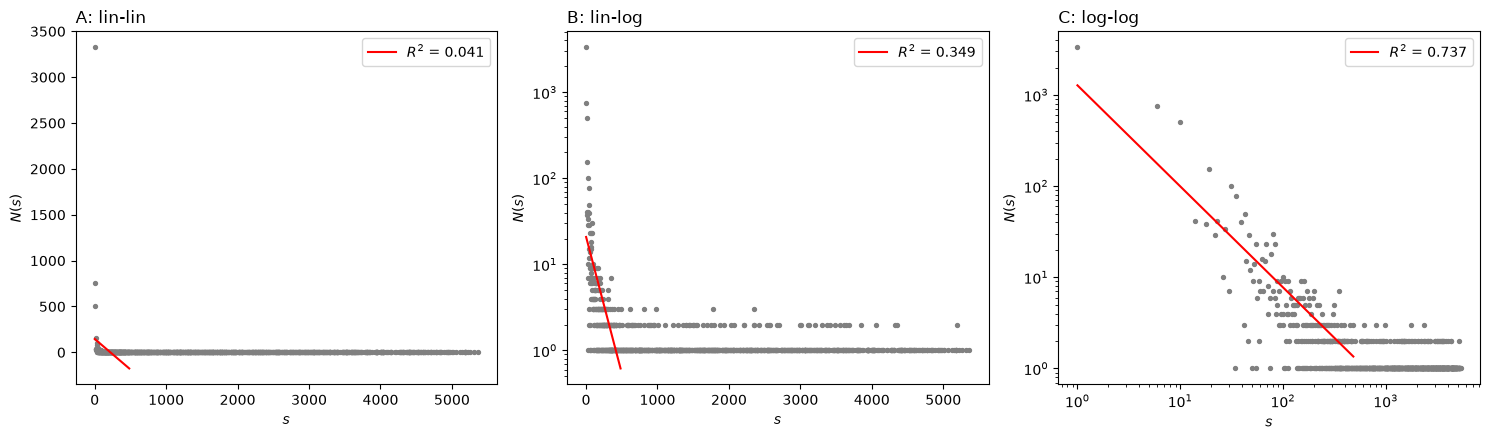

In [8]:
s, N = porazdelitev(rez["s"][T_stac:])
m = (N >= 3) & (s <= 0.1 * s.max())   # izločimo redke dogodke in odrez
s_f, N_f = s[m], N[m]

fig = plt.figure(figsize=(15, 4.5))
modeli = [("linear", "linear", "A: lin-lin", s_f, N_f),
          ("linear", "log", "B: lin-log", s_f, np.log(N_f)),
          ("log", "log", "C: log-log", np.log10(s_f), np.log10(N_f))]
for k, (xs, ys, naslov, X, Y) in enumerate(modeli):
    k_, n_ = np.polyfit(X, Y, 1)
    Y_fit = k_ * X + n_
    R2 = r2(Y, Y_fit)
    ax = fig.add_subplot(1, 3, k + 1)
    ax.scatter(s, N, s=8, color="gray")
    xx = np.sort(s_f)
    if k == 0:
        yy = k_ * xx + n_
        print(f"linearni:    k = {k_:.3g}, n = {n_:.3g}, R2 = {R2:.3f}")
    elif k == 1:
        yy = np.exp(n_) * np.exp(k_ * xx)
        print(f"eksponentni: A = {np.exp(n_):.3g}, B = {-k_:.3g}, R2 = {R2:.3f}")
    else:
        yy = 10 ** n_ * xx ** k_
        print(f"potenčni:    A = {10 ** n_:.3g}, tau = {-k_:.3f}, R2 = {R2:.3f}")
    ax.plot(xx, yy, color="red", label=f"$R^2$ = {R2:.3f}")
    ax.set_xscale(xs)
    ax.set_yscale(ys)
    ax.set_xlabel("$s$")
    ax.set_ylabel("$N(s)$")
    ax.set_title(naslov, loc="left")
    ax.legend()
fig.tight_layout()
plt.show()

# Naloga 4 - Slika 4

S_c | T_stac | <S> | <s> | s_max | tau


  4 |   1124 | 3.21 | 142.0 |  1751 | 1.19


  6 |   1806 | 5.10 | 141.9 |  1767 | 1.21


  8 |   2500 | 7.17 | 141.5 |  1751 | 1.24


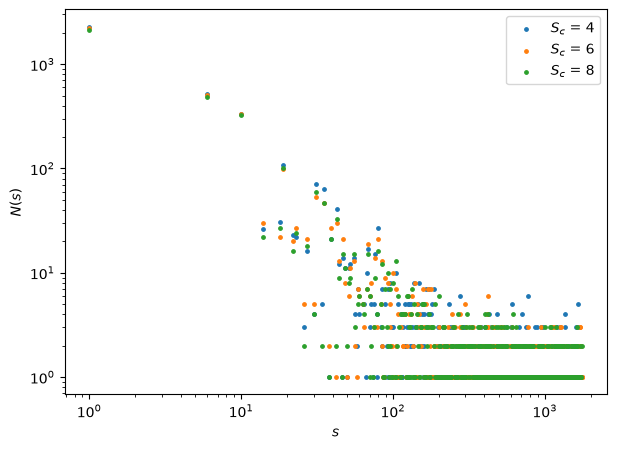

In [9]:
fig = plt.figure(figsize=(7, 5))
ax = fig.add_subplot(111)
print("S_c | T_stac | <S> | <s> | s_max | tau")
for Sc in (4, 6, 8):
    r = simulacija(21, 21, Sc, 1, 20_000)
    T0 = t_stac(r["izguba"])
    s_st = r["s"][T0:]
    s, N = porazdelitev(s_st)
    m = (N >= 3) & (s <= 0.1 * s.max())
    tau = -np.polyfit(np.log10(s[m]), np.log10(N[m]), 1)[0]
    print(f"{Sc:3d} | {T0:6d} | {r['S'].mean():.2f} | {s_st[s_st > 0].mean():.1f} | {s_st.max():5d} | {tau:.2f}")
    ax.scatter(s, N, s=6, label=f"$S_c$ = {Sc}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("$s$")
ax.set_ylabel("$N(s)$")
ax.legend()
plt.show()